First 5 Records
                                     Patient_Problem  \
0  Constant fatigue and muscle weakness, struggli...   
1  Frequent severe migraines, sensitivity to ligh...   
2  Sudden weight gain and feeling cold, especiall...   
3  High fever, sore throat, and swollen lymph nod...   
4  Excessive thirst and frequent urination, dry m...   

                    Disease                                       Prescription  
0  Chronic Fatigue Syndrome  Cognitive behavioral therapy, graded exercise ...  
1        Migraine with Aura  Prescription triptans, avoid triggers like bri...  
2            Hypothyroidism  Levothyroxine to regulate thyroid hormone levels.  
3             Mononucleosis            Rest and hydration, ibuprofen for pain.  
4         Diabetes Mellitus             Insulin therapy and lifestyle changes.  

Dataset Shape: (407, 3)

Total Disease Classes: 178


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.0192 - loss: 5.1797 - val_accuracy: 0.0154 - val_loss: 5.1851
Epoch 2/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0962 - loss: 5.1486 - val_accuracy: 0.0154 - val_loss: 5.1845
Epoch 3/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1000 - loss: 5.1089 - val_accuracy: 0.0154 - val_loss: 5.1833
Epoch 4/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0846 - loss: 5.0413 - val_accuracy: 0.0154 - val_loss: 5.1833
Epoch 5/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0731 - loss: 4.9224 - val_accuracy: 0.0154 - val_loss: 5.2137
Epoch 6/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0692 - loss: 4.7472 - val_accuracy: 0.0154 - val_loss: 5.3114
Epoch 7/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0654 - loss: 4.5605 - val_accuracy: 0.0154 - val_loss: 5.4918
Epoch 8/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0538 - loss: 4.4032 - val_accuracy: 0.0154 - val_loss

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/me

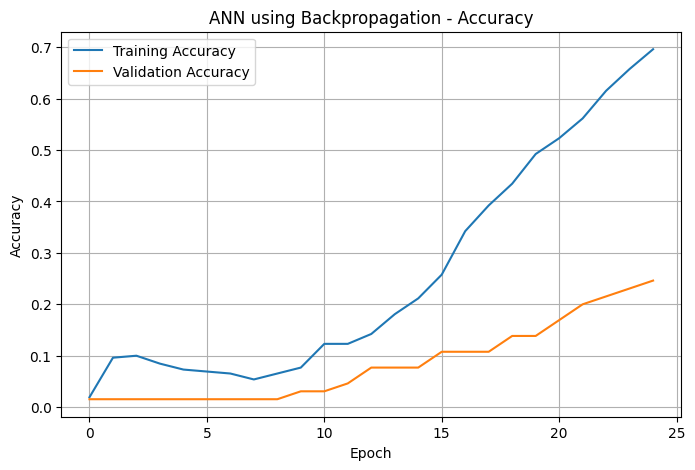

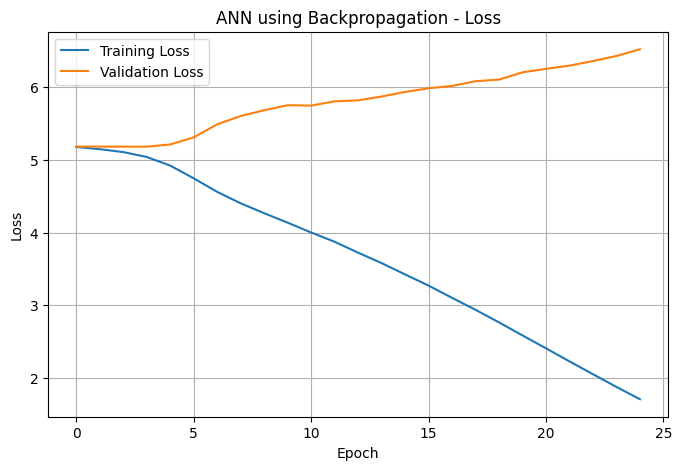

In [ ]:
# =====================================================
# Artificial Neural Network using Backpropagation
# Disease Classification using medical_data.csv
# =====================================================

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# =====================================================
# Step 1: Load Dataset
# =====================================================

# ERROR: FileNotFoundError: [Errno 2] No such file or directory: '/content/medical_data.csv'
# To fix this, please upload the 'medical_data.csv' file to your Colab environment.
# You can do this by clicking the folder icon on the left sidebar, then the 'Upload to session storage' icon.
# Ensure the file is placed in the '/content/' directory.
data = pd.read_csv("/content/medical_data.csv")

print("First 5 Records")
print(data.head())

print("\nDataset Shape:", data.shape)

# =====================================================
# Step 2: Input and Output
# =====================================================

X = data["Patient_Problem"]
y = data["Disease"]

# =====================================================
# Step 3: Convert Text to Numerical Features
# =====================================================

vectorizer = TfidfVectorizer(max_features=1000)

X = vectorizer.fit_transform(X).toarray()

# =====================================================
# Step 4: Encode Target Labels
# =====================================================

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("\nTotal Disease Classes:", len(np.unique(y)))

# =====================================================
# Step 5: Split Dataset
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# =====================================================
# Step 6: Build ANN
# =====================================================

model = Sequential()

# Input Layer + Hidden Layer
model.add(Dense(
    units=64,
    activation='relu',
    input_shape=(X_train.shape[1],)
))

# Hidden Layer
model.add(Dense(
    units=32,
    activation='relu'
))

# Output Layer
model.add(Dense(
    units=len(np.unique(y)),
    activation='softmax'
))

# =====================================================
# Step 7: Compile Model
# =====================================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# =====================================================
# Step 8: Train Model
# Backpropagation occurs automatically here
# =====================================================

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=25,
    batch_size=16,
    verbose=1
)

# =====================================================
# Step 9: Evaluate Model
# =====================================================

loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Accuracy :", accuracy)

# =====================================================
# Step 10: Prediction
# =====================================================

y_pred = model.predict(X_test)

predicted = np.argmax(y_pred, axis=1)

# =====================================================
# Step 11: Performance Metrics
# =====================================================

print("\nAccuracy Score")
print(accuracy_score(y_test, predicted))

print("\nClassification Report")
print(classification_report(
    y_test,
    predicted,
    labels=np.unique(y), # Added to specify all possible labels
    target_names=encoder.classes_
))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, predicted))

# =====================================================
# Step 12: Predict New Patient Problems
# =====================================================

sample = [
    "High fever with headache",
    "Chest pain and breathing difficulty",
    "Sneezing and sore throat",
    "Stomach pain with vomiting"
]

sample_vector = vectorizer.transform(sample).toarray()

prediction = model.predict(sample_vector)

disease = encoder.inverse_transform(
    np.argmax(prediction, axis=1)
)

print("\nSample Predictions")

for s, d in zip(sample, disease):
    print("Patient Problem :", s)
    print("Predicted Disease :", d)
    print("--------------------------------")

# =====================================================
# Step 13: Accuracy Graph
# =====================================================

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("ANN using Backpropagation - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# Step 14: Loss Graph
# =====================================================

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("ANN using Backpropagation - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()